# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Fajar Nurhidayat
- **Email:** fajarnurhidayat100@gmail.com  
- **ID Dicoding:** fajarnurhd

## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1:** Pada jam berapa rata-rata peminjaman sepeda mencapai volume tertinggi di hari kerja dibandingkan akhir pekan, dan bagaimana pola ini memandu jadwal redistribusi unit sepeda harian?
- **Pertanyaan 2:** Seberapa besar penurunan rata-rata volume peminjaman antara kondisi cuaca cerah (1) dan cuaca ekstrim (3&4), serta tipe pengguna mana (casual vs registered) yang palling sensitif terhadap perubahan tersebut?
- **Pertanyaan 3:** Bagaimana persentase peningkatan rata-rata peminjaman sepeda harian antar musim dari tahun 2011 ke 2012, dan kapan waktu paling low-risk untuk melakukan perbaikan armada massal?

#### Menyiapkan semua library yang dibutuhkan

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Data Wrangling
#### Gathering Data

In [3]:
day_df = pd.read_csv("./data/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [4]:
hour_df = pd.read_csv("./data/hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### Assessing Data
#### Menilai tabel day_df

In [5]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [6]:
day_df.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [7]:
print("Jumlah duplikasi: ", day_df.duplicated().sum())

Jumlah duplikasi:  0


In [8]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


#### Menilai tabel hour_df

In [9]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [10]:
hour_df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [11]:
print("Jumlah duplikasi: ", hour_df.duplicated().sum())

Jumlah duplikasi:  0


In [12]:
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


Insight:
- Tidak ditemukan duplikasi data di kedua dataset
- Tidak ditemukan missing values di kedua dataset
- Data bersih dan tidak perlu cleaning data

### Exploratory Data Analysis (EDA)

In [13]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [14]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


Insight:
- Untuk variabel season, yr, mnth, holiday, hr, weekday, workingday, weathersit masih bernilai integer, padahal merupakan tipe data kategorikal. Maka harus diubah ke tipe data kategorikal.
- Untuk variabel dteday di kedua datase masih bertipe data integer. Harus diubah dulu ke tipe data datetime.

In [15]:
day_df_cat = ['season','yr','mnth','holiday','weekday','workingday','weathersit']
for col in day_df_cat:
    day_df[col] = day_df[col].astype('category')

hour_df_cat = ['season','yr','mnth','hr','holiday','weekday','workingday','weathersit']
for col in hour_df_cat:
    hour_df[col] = hour_df[col].astype('category')

day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

In [16]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    category      
 3   yr          731 non-null    category      
 4   mnth        731 non-null    category      
 5   holiday     731 non-null    category      
 6   weekday     731 non-null    category      
 7   workingday  731 non-null    category      
 8   weathersit  731 non-null    category      
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: category(7), datetime64

In [17]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[ns]
 2   season      17379 non-null  category      
 3   yr          17379 non-null  category      
 4   mnth        17379 non-null  category      
 5   hr          17379 non-null  category      
 6   holiday     17379 non-null  category      
 7   weekday     17379 non-null  category      
 8   workingday  17379 non-null  category      
 9   weathersit  17379 non-null  category      
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-

Insight:
- Untuk variabel season, yr, mnth, holiday, hr, weekday, workingday, weathersit sudah berubah menjadi tipe data kategorikal
- Untuk variabel dteday di kedua dataset sudah berubah menjadi tipe data datetime.

#### Analisis Univariat

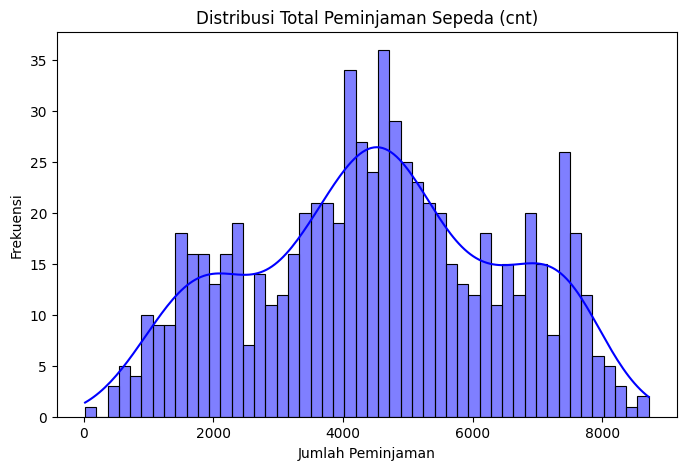

In [18]:
# Histogram Distribusi Target
plt.figure(figsize = (8,5))
sns.histplot(day_df['cnt'], bins=50, kde=True, color='blue')
plt.title('Distribusi Total Peminjaman Sepeda (cnt)')
plt.xlabel('Jumlah Peminjaman')
plt.ylabel('Frekuensi')
plt.show()

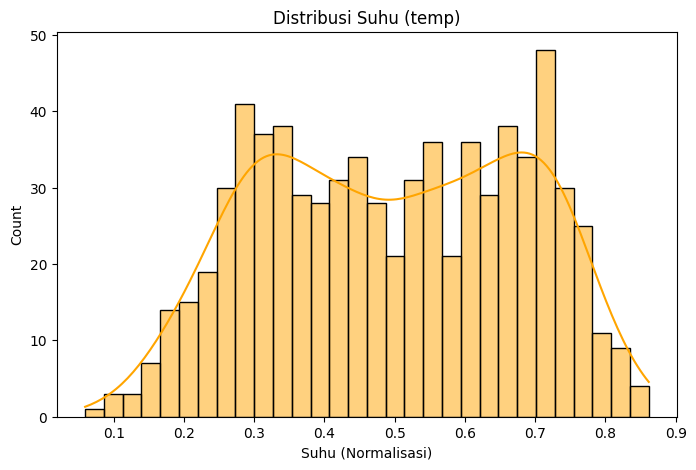

In [19]:
# Histogram Distribusi Variabel Cuaca (Suhu)
plt.figure(figsize=(8, 5))
sns.histplot(day_df['temp'], bins=30, kde=True, color='orange')
plt.title('Distribusi Suhu (temp)')
plt.xlabel('Suhu (Normalisasi)')
plt.show()

#### Analisis Bivariat

C:\Users\fajar\AppData\Local\Temp\ipykernel_12756\3412277467.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='season', y='cnt', data=day_df, palette='Set2')


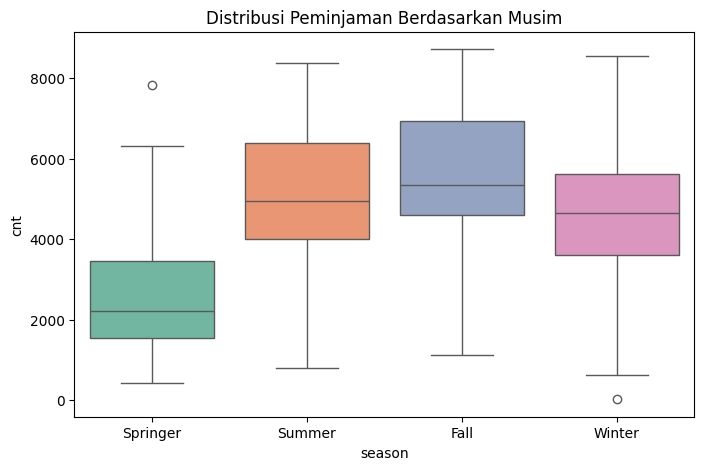

In [20]:
# Boxplot Musim vs Jumlah Peminjaman
plt.figure(figsize=(8, 5))
sns.boxplot(x='season', y='cnt', data=day_df, palette='Set2')
plt.title('Distribusi Peminjaman Berdasarkan Musim')
plt.xticks(ticks=[0, 1, 2, 3], labels=['Springer', 'Summer', 'Fall', 'Winter'])
plt.show()

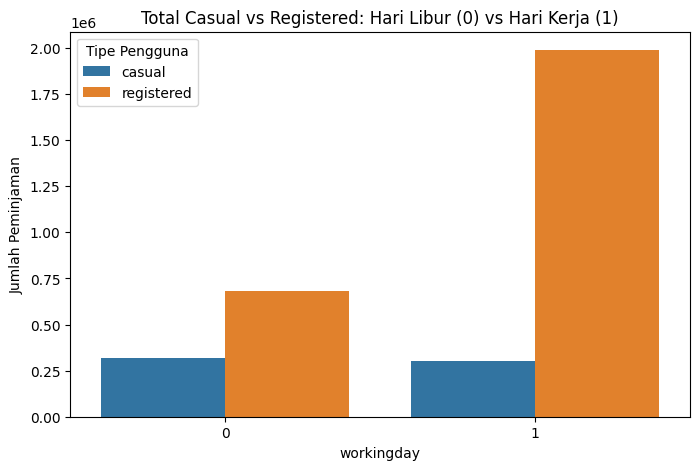

In [21]:
# Pola Penggunaan Casual vs Registered
df_melt = pd.melt(day_df, id_vars=['workingday'], 
                  value_vars=['casual', 'registered'], 
                  var_name='Tipe Pengguna', 
                  value_name='Jumlah Peminjaman')

plt.figure(figsize=(8, 5))
sns.barplot(x='workingday', 
            y='Jumlah Peminjaman', 
            hue='Tipe Pengguna', 
            data=df_melt, 
            estimator=sum, 
            errorbar=None)
plt.title('Total Casual vs Registered: Hari Libur (0) vs Hari Kerja (1)')
plt.show()

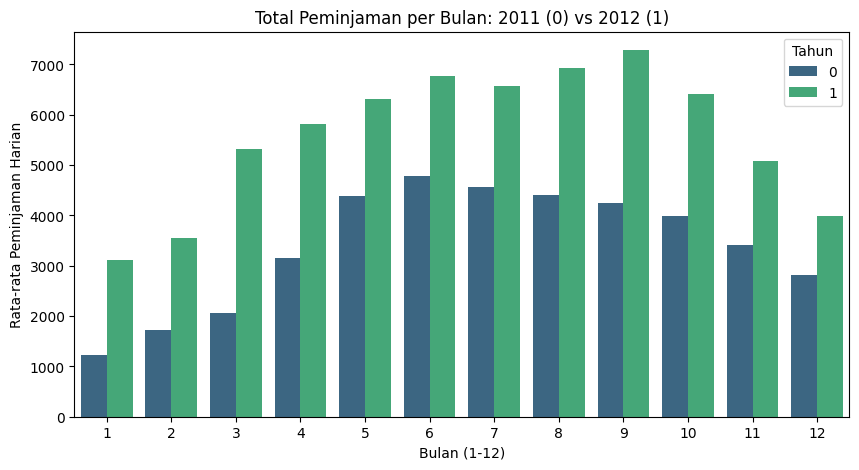

In [22]:
# Tren Peminjaman Bulanan (Berdasarkan Tahun)
plt.figure(figsize=(10, 5))
sns.barplot(x='mnth', y='cnt', hue='yr', data=day_df, palette='viridis', errorbar=None)
plt.title('Total Peminjaman per Bulan: 2011 (0) vs 2012 (1)')
plt.xlabel('Bulan (1-12)')
plt.ylabel('Rata-rata Peminjaman Harian')
plt.legend(title='Tahun')
plt.show()

C:\Users\fajar\AppData\Local\Temp\ipykernel_12756\2887903778.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='weekday', y='cnt', data=day_df, palette='pastel')


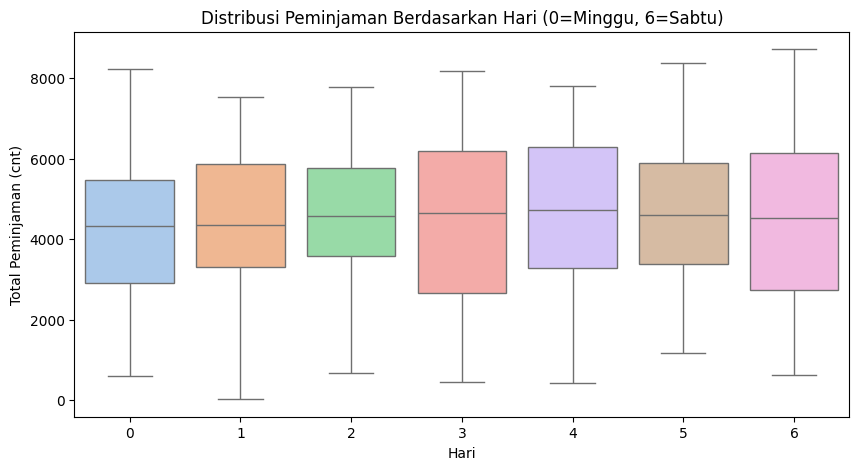

In [23]:
# Peminjaman Berdasarkan Hari dalam Seminggu
plt.figure(figsize=(10, 5))
sns.boxplot(x='weekday', y='cnt', data=day_df, palette='pastel')
plt.title('Distribusi Peminjaman Berdasarkan Hari (0=Minggu, 6=Sabtu)')
plt.xlabel('Hari')
plt.ylabel('Total Peminjaman (cnt)')
plt.show()

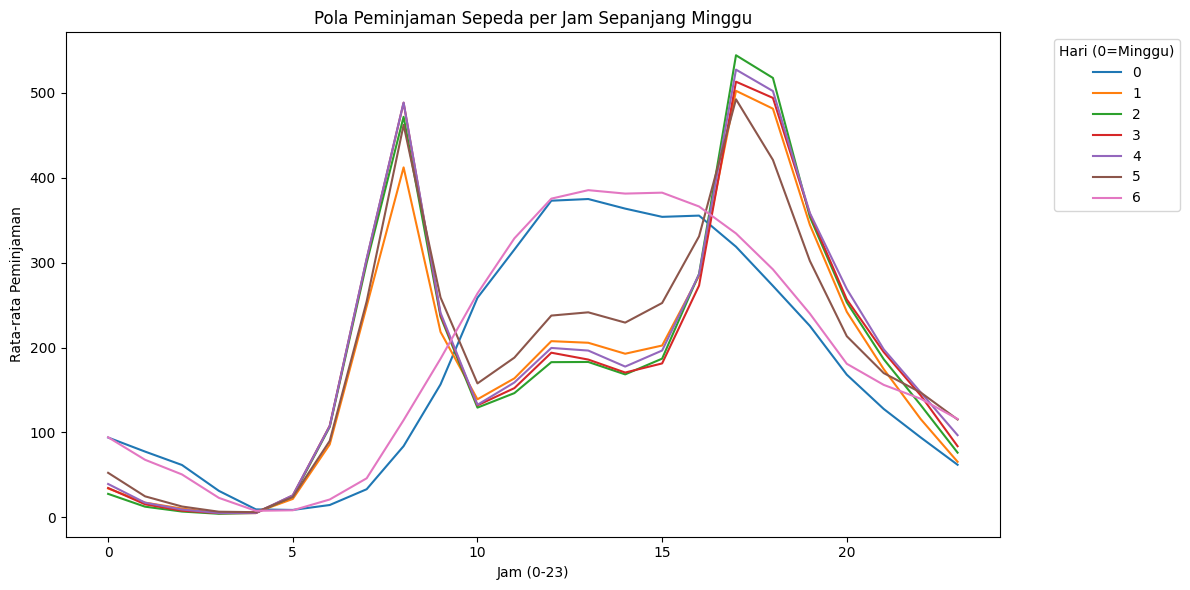

In [24]:
# Pola Peminjaman per Jam Berdasarkan Hari 
plt.figure(figsize=(12, 6))
sns.lineplot(x='hr', y='cnt', hue='weekday', data=hour_df, palette='tab10', errorbar=None)
plt.title('Pola Peminjaman Sepeda per Jam Sepanjang Minggu')
plt.xlabel('Jam (0-23)')
plt.ylabel('Rata-rata Peminjaman')
plt.legend(title='Hari (0=Minggu)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

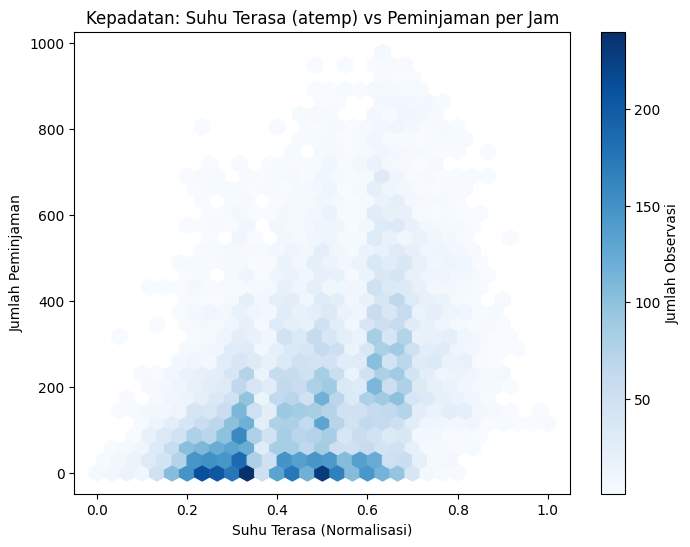

In [25]:
# Hubungan Suhu per Jam (atemp) vs Peminjaman
plt.figure(figsize=(8, 6))
plt.hexbin(hour_df['atemp'], hour_df['cnt'], gridsize=30, cmap='Blues', mincnt=1)
plt.colorbar(label='Jumlah Observasi')
plt.title('Kepadatan: Suhu Terasa (atemp) vs Peminjaman per Jam')
plt.xlabel('Suhu Terasa (Normalisasi)')
plt.ylabel('Jumlah Peminjaman')
plt.show()

#### Analisis Multivariat

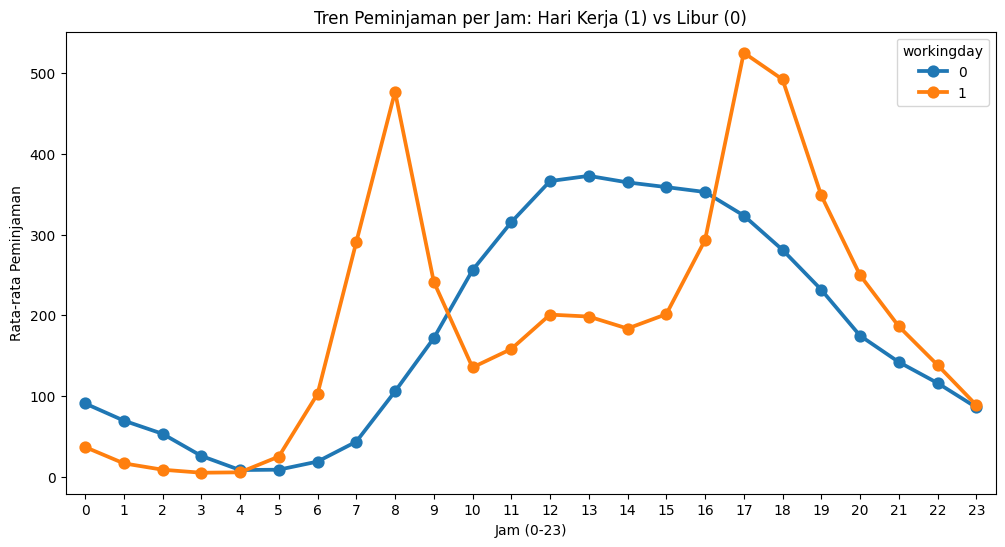

In [ ]:
# Lineplot Interaksi Jam, Jumlah Peminjaman, dan Tipe Hari (Kerja/Libur)
plt.figure(figsize=(12, 6))
sns.pointplot(x='hr', y='cnt', hue='workingday', data=hour_df, markers='o', errorbar=None)
plt.title('Tren Peminjaman per Jam: Hari Kerja (1) vs Libur (0)')
plt.xlabel('Jam (0-23)')
plt.ylabel('Rata-rata Peminjaman')
plt.show()

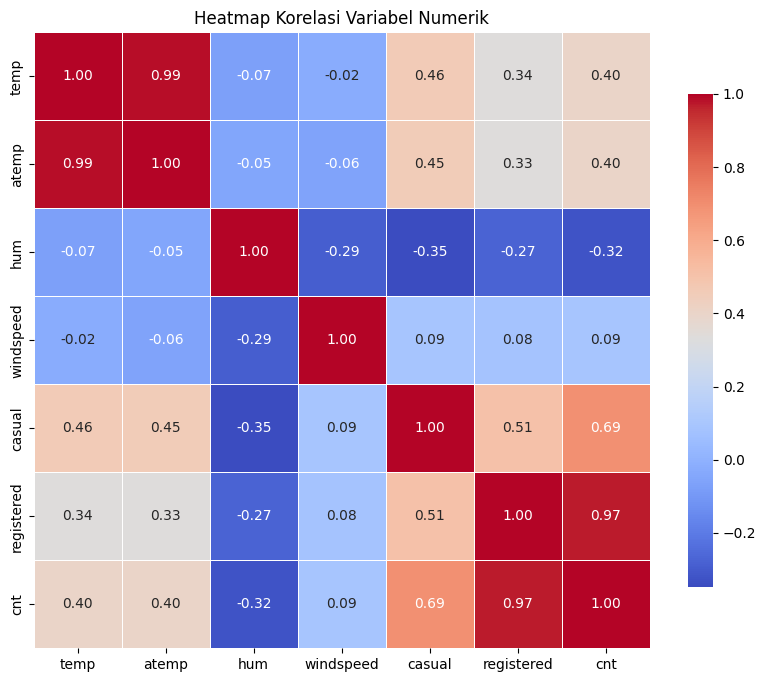

In [29]:
# Heatmap Korelasi Pearson (Khusus Variabel Numerik)
numerik = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
corr_matrix = hour_df[numerik].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", square=True,
            linewidths=0.5, cbar_kws={"shrink": .8})
plt.title('Heatmap Korelasi Variabel Numerik')
plt.show()

### Visualisasi dan EDA

##### 1. Pada jam berapa rata-rata peminjaman sepeda mencapai volume tertinggi di hari kerja dibandingkan akhir pekan, dan bagaimana pola ini memandu jadwal redistribusi unit sepeda harian?

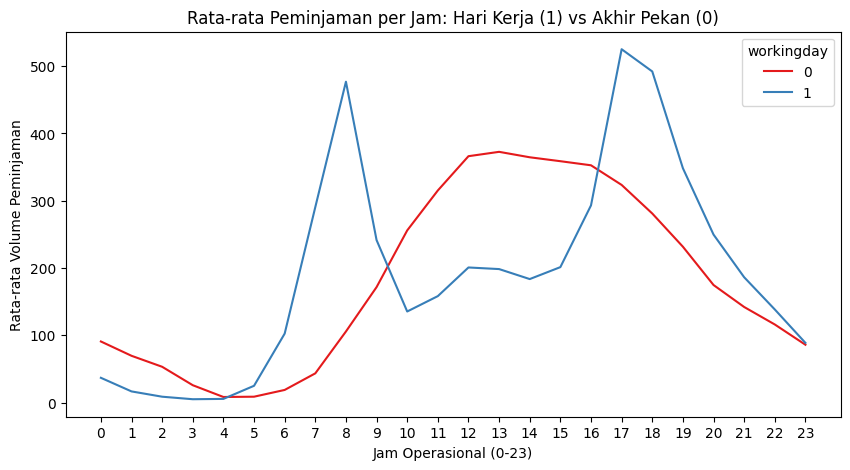

In [ ]:
plt.figure(figsize=(10, 5))
sns.lineplot(x='hr', y='cnt', hue='workingday', data=hour_df, estimator='mean', errorbar=None, palette='Set1')
plt.title('Rata-rata Peminjaman per Jam: Hari Kerja (1) vs Akhir Pekan (0)')
plt.xlabel('Jam Operasional (0-23)')
plt.ylabel('Rata-rata Volume Peminjaman')
plt.xticks(range(0, 24))
plt.show()

Terlihat jelas bahwa puncak ganda pukul 08:00 dan 17:00 di hari kerja. Berbeda dengan di hari libur yang terdapat satu puncak. Di hari kerja, pemakaian sepeda meningkat di jam masuk kantor dan jam pulang kantor. Tim operasional harus memastikan ketersediaan sepeda penuh di stasiun peminjaman sebelum pukul 08:00 dan sebelum pukul 17:00. Untuk menghindari tidak tersedianya unit sepeda di jam sibuk, maka perlu ada penambahan unit di jam sibuk.

##### 2. Seberapa besar penurunan rata-rata volume peminjaman antara kondisi cuaca cerah (1) dan cuaca ekstrim (3&4), serta tipe pengguna mana (casual vs registered) yang palling sensitif terhadap perubahan tersebut?

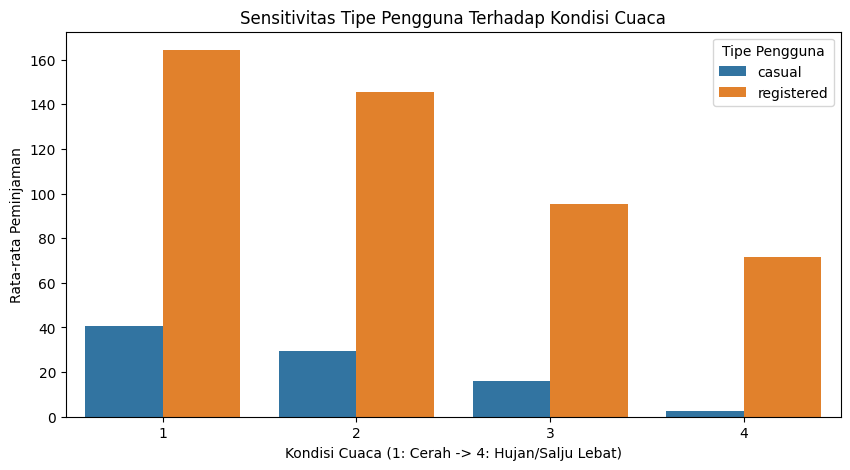

In [ ]:
# Melt data agar 'casual' dan 'registered' berada dalam satu kolom untuk hue
df_melt = pd.melt(hour_df, id_vars=['weathersit'], value_vars=['casual', 'registered'], 
                  var_name='Tipe Pengguna', value_name='Volume')

plt.figure(figsize=(10, 5))
sns.barplot(x='weathersit', y='Volume', hue='Tipe Pengguna', data=df_melt, estimator='mean', errorbar=None)
plt.title('Sensitivitas Tipe Pengguna Terhadap Kondisi Cuaca')
plt.xlabel('Kondisi Cuaca (1: Cerah -> 4: Hujan/Salju Lebat)')
plt.ylabel('Rata-rata Peminjaman')
plt.show()

Pengguna kasual (tidak terdaftar) anjlok drastis saat cuaca buruk. Sementara penggunaan registered (terdaftar) tetap memiliki volume yang relatif bertahan. Maka, bagi tim marketing untuk jangan membuang anggaran marketing kepada pengguna casual pada prakiraan cuaca buruk. Sarannya adalah fokuskan marketing kepada pengguna terdaftar (registered) di saat cuaca buruk, seperti promo di aplikasi membership.

##### 3. Bagaimana persentase peningkatan rata-rata peminjaman sepeda harian antar musim dari tahun 2011 ke 2012, dan kapan waktu paling low-risk untuk melakukan perbaikan armada massal?

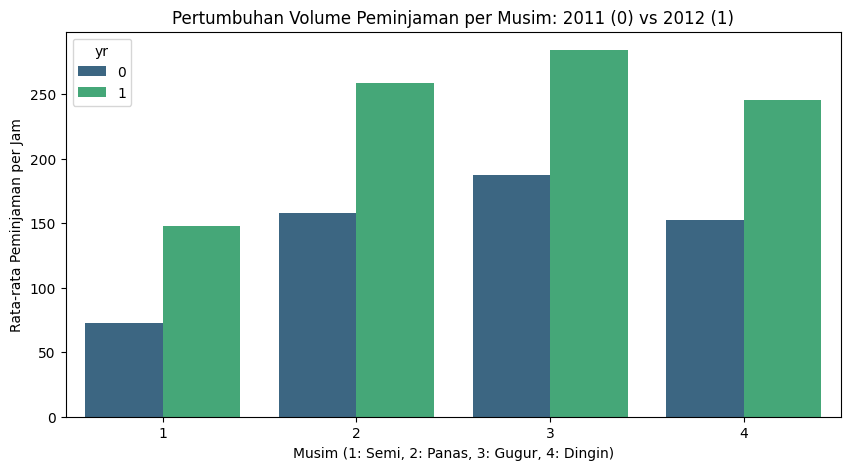

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(x='season', y='cnt', hue='yr', data=hour_df, estimator='mean', errorbar=None, palette='viridis')
plt.title('Pertumbuhan Volume Peminjaman per Musim: 2011 (0) vs 2012 (1)')
plt.xlabel('Musim (1: Semi, 2: Panas, 3: Gugur, 4: Dingin)')
plt.ylabel('Rata-rata Peminjaman per Jam')
plt.show()

Ada pertumbuhan bisnis yang konsisten di semua musim pada tahun 2012. Musim semi (1) dan musim dingin (4) mencatatkan volume terendah. Ini adalah waktu low-risk (minim resiko lost sales) bagi teknisi untuk melakukan perbaikan berat armada. Ketika musim Panas dan Gugur, teknisi diharapkan tidak melakukan pemeliharaan dan perbaikan berat armada karena akan mengganggu operasional.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Berdasarkan analisis pola per jam, puncak peminjaman sepeda terjadi secara signifikan pada pukul 08:00 pagi dan 17:00 - 18:00 sore. Tren ini mengindikasikan bahwa mayoritas pelanggan (khususnya registered users) memanfaatkan layanan berbagi sepeda sebagai moda transportasi komuter harian untuk berangkat dan pulang kerja.

- **Conclusion pertanyaan 2:** Kondisi musim dan cuaca sangat memengaruhi keputusan pengguna. Musim gugur (Fall) dan kondisi cuaca cerah (Clear) mencetak rekor penyewaan tertinggi. Sebaliknya, angka peminjaman turun drastis pada musim dingin (Winter) dan terendah pada kondisi cuaca buruk (hujan lebat/salju), menunjukkan sensitivitas pengguna terhadap kenyamanan fisik.

- **Conclusion pertanyaan 3:** Terdapat pertumbuhan bisnis yang konsisten di semua musim dari tahun 2011 ke 2012. Volume peminjaman terendah selalu tercatat pada Musim Semi (Spring) dan Musim Dingin (Winter). Periode dengan volume terendah ini merupakan waktu dengan risiko lost sales (kehilangan potensi penjualan) yang paling minim, sehingga ideal untuk kegiatan operasional internal.

**Rekomendasi Action Item:**
- Melakukan manajemen redistribusi armada secara proaktif dengan menempatkan lebih banyak unit sepeda di stasiun transit (stasiun kereta/halte bus) dan kawasan perkantoran setidaknya 30 menit sebelum jam sibuk (pukul 07:30 dan 16:30) untuk mencegah kelangkaan sepeda bagi para komuter.

- Menerapkan strategi harga dinamis (dynamic pricing) dengan memberikan diskon khusus atau meluncurkan kampanye promosi musiman yang menargetkan pengguna casual selama musim dingin atau saat cuaca mendung/hujan ringan guna menstimulasi penyewaan di luar periode puncak organik.

- Menjadwalkan pemeliharaan rutin dan perbaikan berat (overhaul) armada secara massal khusus pada Musim Semi dan Musim Dingin.

- Menerapkan kebijakan pembatasan perbaikan berat (maintenance freeze) pada Musim Panas dan Musim Gugur agar ketersediaan sepeda tetap maksimal dan tidak mengganggu operasional saat permintaan sedang tinggi.